# Automobile Price Analysis — Namubiru

**Data Science Lifecycle — Assignment One (Advent 2026)**  
**Student:** Namubiru  
**Objective:** Explore and model automobile prices using descriptive statistics, SciPy tests, and classical OLS/ANOVA methods.

The notebook uses `automobileEDA.csv` as the raw input when it is available beside this notebook. It preserves original measurements, creates explicit winsorized columns, and saves the cleaned data as `Namubiru_Data.csv`. The supplied dataset is small and observational, so findings are associations rather than causal effects.

## Setup and source data

In [1]:
from pathlib import Path
import warnings
import re

import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from scipy.stats import boxcox
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.gofplots import qqplot

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

RAW_FILE = Path("automobileEDA.csv")
CLEAN_FILE = Path("Namubiru_Data.csv")
if not RAW_FILE.exists():
    raise FileNotFoundError(
        "Place automobileEDA.csv in the notebook folder to reproduce the analysis."
    )

raw_df = pd.read_csv(RAW_FILE)
df = raw_df.copy()
print(f"Raw dataset: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Raw missing cells: {int(df.isna().sum().sum())}")

Raw dataset: 201 rows × 29 columns
Raw missing cells: 5


The loaded raw file contains **201 rows × 29 columns** and **5 missing cells**. These counts establish the baseline before cleaning; the row count is retained throughout the analysis.

## Question 1 — Data quality and cleaning

In [2]:
numeric_columns = df.select_dtypes(include="number").columns
quality = pd.DataFrame(index=df.columns)
quality["dtype"] = df.dtypes.astype(str)
quality["missing_count"] = df.isna().sum()
quality["unique_values"] = df.nunique(dropna=True)
quality["min"] = [
    df[column].min() if column in numeric_columns else np.nan
    for column in df.columns
]
quality["max"] = [
    df[column].max() if column in numeric_columns else np.nan
    for column in df.columns
]
quality["zero_count"] = [
    int(df[column].eq(0).sum()) for column in df.columns
]
display(quality)
print(f"Rows × columns: {df.shape}; total missing cells: {int(df.isna().sum().sum())}")

,dtype,missing_count,unique_values,min,max,zero_count
symboling,int64,0,6,-2.0000,3.0000,65
normalized-losses,int64,0,51,65.0000,256.0000,0
make,str,0,22,NaN,NaN,0
aspiration,str,0,2,NaN,NaN,0
num-of-doors,str,0,2,NaN,NaN,0
body-style,str,0,5,NaN,NaN,0
drive-wheels,str,0,3,NaN,NaN,0
engine-location,str,0,2,NaN,NaN,0
wheel-base,float64,0,52,86.6000,120.9000,0
length,float64,0,73,0.6780,1.0000,0


Rows × columns: (201, 29); total missing cells: 5


The report covers all **29 fields**. It finds **4 missing `stroke` values** and **1 missing `horsepower-binned` value**; every other field is complete. Numeric prices range from **$5,118 to $45,400** and `make` has **22** levels. Zero counts are useful for indicator fields: `diesel` is 0 for **181** cars and `gas` is 0 for **20**. Text-category min/max are left blank because a lexical endpoint is not a meaningful numeric range.

In [3]:
# Impute stroke within engine type; use the overall median only when that group has no observed strokes.
overall_stroke_median = df["stroke"].median()
engine_stroke_medians = df.groupby("engine-type")["stroke"].transform("median")
df["stroke"] = df["stroke"].fillna(engine_stroke_medians).fillna(overall_stroke_median)

# Rebuild the category from the measured horsepower; open-ended limits cover all observed values.
horsepower_bins = [-np.inf, 100, 200, np.inf]
horsepower_labels = ["Low", "Medium", "High"]
df["horsepower-binned"] = pd.cut(
    df["horsepower"],
    bins=horsepower_bins,
    labels=horsepower_labels,
    include_lowest=True,
    right=True,
)

duplicates_all = int(raw_df.duplicated().sum())
duplicates_except_price = int(raw_df.drop(columns="price").duplicated().sum())

# Preserve original numeric values and create 1st/99th-percentile winsorized columns.
continuous_features = [
    column for column in df.select_dtypes(include="number").columns
    if column not in {"symboling", "diesel", "gas"}
]
winsor_summary = []
for column in continuous_features:
    lower = df[column].quantile(0.01)
    upper = df[column].quantile(0.99)
    clipped = df[column].clip(lower=lower, upper=upper)
    df[f"{column}_winsorized"] = clipped
    winsor_summary.append(
        {
            "variable": column,
            "p01": lower,
            "p99": upper,
            "observations_clipped": int((clipped != df[column]).sum()),
        }
    )

print(f"Overall stroke median used as fallback: {overall_stroke_median:.4f}")
print(f"Missing stroke after imputation: {int(df['stroke'].isna().sum())}")
print(f"Missing horsepower-binned after recalculation: {int(df['horsepower-binned'].isna().sum())}")
print(f"Rows outside horsepower bins: {int(df['horsepower-binned'].isna().sum())}")
print(f"Exact duplicate rows (all columns): {duplicates_all}")
print(f"Duplicate feature rows (excluding price): {duplicates_except_price}")
display(pd.DataFrame(winsor_summary).set_index("variable"))

Overall stroke median used as fallback: 3.2900
Missing stroke after imputation: 0
Missing horsepower-binned after recalculation: 0
Rows outside horsepower bins: 0
Exact duplicate rows (all columns): 0
Duplicate feature rows (excluding price): 7


,p01,p99,observations_clipped
variable,,,
normalized-losses,65.0000,197.0000,2
wheel-base,88.4000,115.6000,3
length,0.6949,0.9736,2
width,0.8681,0.9958,3
height,48.8000,59.1000,3
curb-weight,"1,819.0000","3,950.0000",4
engine-size,70.0000,304.0000,3
bore,2.9100,3.8000,3
stroke,2.1900,3.9000,3


The **4** missing strokes are filled within engine type, with overall median **3.2900** as the fallback; no missing strokes remain. Recomputed horsepower bins leave **0** cars outside the open-ended bins. There are **0 exact duplicate rows**, but **7 repeated feature profiles** after excluding price; those are retained because their observed prices differ. The **16** continuous numeric fields keep their originals and receive new winsorized columns; for example, **4 prices** are clipped to the **$5,195–$40,960** 1st/99th-percentile limits.

In [4]:
# Compare |z| > 3 with the conventional 1.5×IQR rule on the cleaned continuous variables.
z_scores = pd.DataFrame(
    stats.zscore(df[continuous_features], nan_policy="omit", ddof=0),
    columns=continuous_features,
    index=df.index,
)
outlier_rows = []
for column in continuous_features:
    values = df[column]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    z_mask = z_scores[column].abs() > 3
    iqr_mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    outlier_rows.append(
        {
            "variable": column,
            "z_score_n": int(z_mask.sum()),
            "IQR_n": int(iqr_mask.sum()),
            "z_only_n": int((z_mask & ~iqr_mask).sum()),
            "IQR_only_n": int((iqr_mask & ~z_mask).sum()),
        }
    )
outlier_report = pd.DataFrame(outlier_rows).set_index("variable")
display(outlier_report)
print(
    "Rows with at least one z-score flag:",
    int((z_scores.abs() > 3).any(axis=1).sum()),
)
print(
    "Rows with at least one IQR flag:",
    int(
        pd.DataFrame(
            {
                column: (df[column] < df[column].quantile(0.25) - 1.5 * (df[column].quantile(0.75) - df[column].quantile(0.25)))
                | (df[column] > df[column].quantile(0.75) + 1.5 * (df[column].quantile(0.75) - df[column].quantile(0.25)))
                for column in continuous_features
            }
        ).any(axis=1).sum()
    ),
)

,z_score_n,IQR_n,z_only_n,IQR_only_n
variable,,,,
normalized-losses,2,8,0,6
wheel-base,1,3,0,2
length,0,1,0,1
width,0,11,0,11
height,0,0,0,0
curb-weight,0,2,0,2
engine-size,5,10,0,5
bore,0,0,0,0
stroke,3,20,0,17


Rows with at least one z-score flag: 26


Rows with at least one IQR flag: 71


Across continuous fields, **26 rows** have at least one **|z| > 3** flag, while the IQR rule flags **71 rows**. The IQR rule is more sensitive here: for example, compression ratio has **9** z-score flags versus **27** IQR flags, and width has **0** versus **11**. This distribution-sensitive difference supports capping rather than deleting observations; every one of the **201 cars** remains.

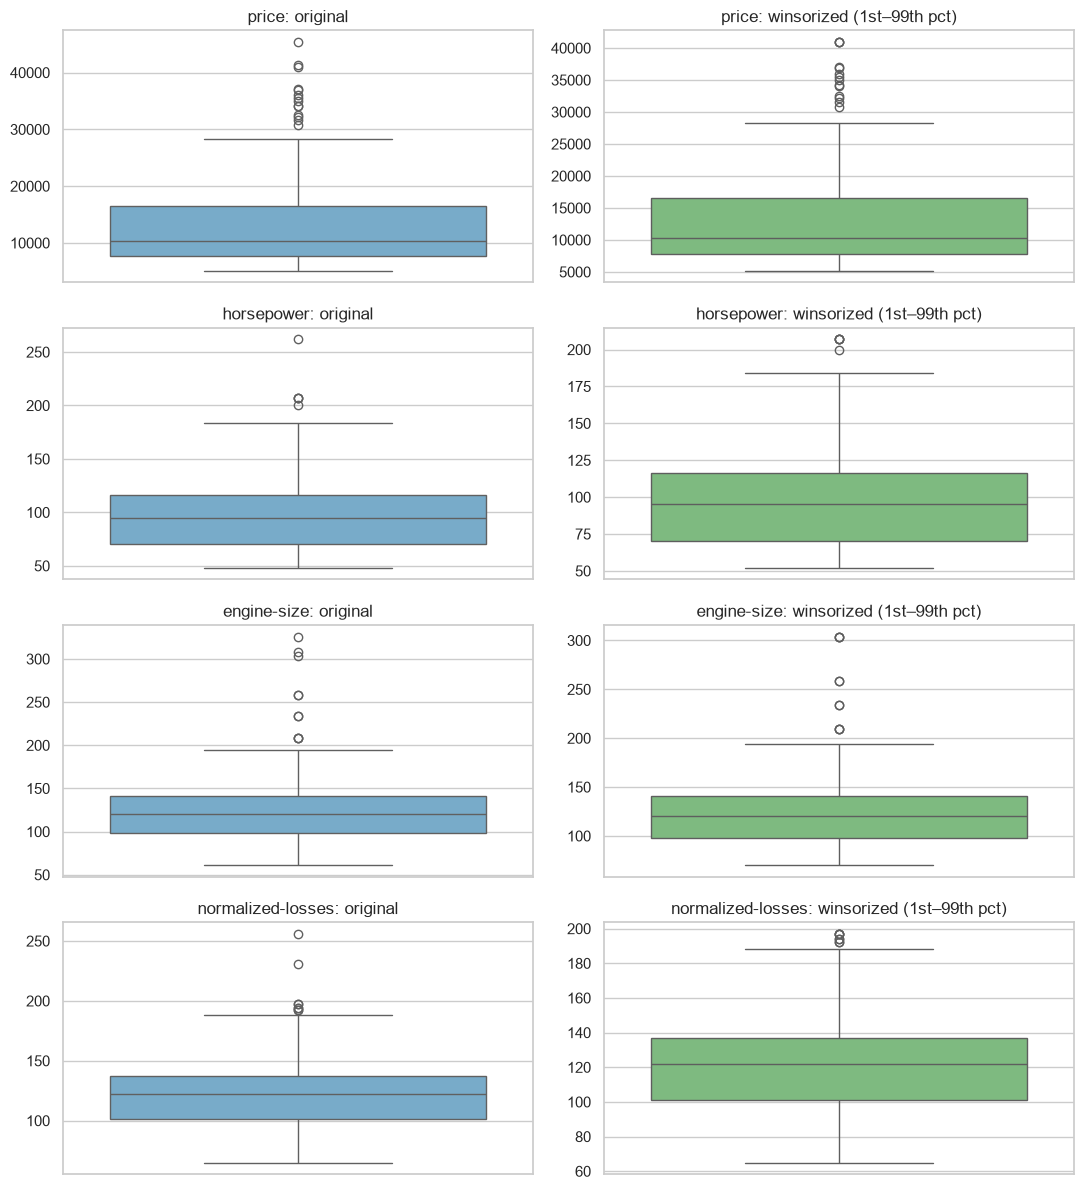

,p01,p99,observations_clipped
variable,,,
price,"5,195.0000","40,960.0000",4
horsepower,52.0000,207.0000,2
engine-size,70.0000,304.0000,3
normalized-losses,65.0000,197.0000,2


In [5]:
box_variables = ["price", "horsepower", "engine-size", "normalized-losses"]
fig, axes = plt.subplots(len(box_variables), 2, figsize=(11, 3 * len(box_variables)))
for row, column in enumerate(box_variables):
    sns.boxplot(y=df[column], ax=axes[row, 0], color="#6baed6")
    axes[row, 0].set_title(f"{column}: original")
    sns.boxplot(y=df[f"{column}_winsorized"], ax=axes[row, 1], color="#74c476")
    axes[row, 1].set_title(f"{column}: winsorized (1st–99th pct)")
    axes[row, 0].set_ylabel("")
    axes[row, 1].set_ylabel("")
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(winsor_summary)
    .set_index("variable")
    .loc[box_variables, ["p01", "p99", "observations_clipped"]]
)

The before/after box plots show that the upper/lower tails are capped without changing the sample size. In the displayed examples, the price limits are **$5,195–$40,960** with **4** values clipped, horsepower **52–207** with **2**, engine size **70–304** with **3**, and normalized losses **65–197** with **2**. All original values remain beside those winsorized versions.

In [6]:
CLEAN_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN_FILE, index=False)
print(f"Saved {CLEAN_FILE.resolve()} ({len(df)} rows × {df.shape[1]} columns)")

Saved C:\Users\HP\Desktop\ucu\DATA SCIENCE LIFE CYCLE\assignment 1\Assignment1_Namubiru\Namubiru_Data.csv (201 rows × 45 columns)


The cleaned file was saved as **`Namubiru_Data.csv`** with **201 rows × 45 columns**: the original 29 fields plus 16 winsorized fields. The cleaning checks above leave **0 missing strokes** and **0 unbinned horsepower values**.

## Question 2 — Descriptive statistics and distributions

In [7]:
summary_rows = []
for column in dict.fromkeys(continuous_features + ["price"]):
    values = df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    summary_rows.append(
        {
            "variable": column,
            "n": values.size,
            "mean": values.mean(),
            "trimmed_mean_10pct": stats.trim_mean(values, 0.10),
            "median": values.median(),
            "std": values.std(),
            "IQR": q3 - q1,
            "skewness": stats.skew(values, bias=False),
            "excess_kurtosis": stats.kurtosis(values, fisher=True, bias=False),
            "min": values.min(),
            "max": values.max(),
        }
    )
summary_stats = pd.DataFrame(summary_rows).set_index("variable")
display(summary_stats)

,n,mean,trimmed_mean_10pct,median,std,IQR,skewness,excess_kurtosis,min,max
variable,,,,,,,,,,
normalized-losses,201,122.0000,119.8820,122.0000,31.9962,36.0000,0.8465,1.3191,65.0000,256.0000
wheel-base,201,98.7970,98.1186,97.0000,6.0664,7.9000,1.0313,0.9484,86.6000,120.9000
length,201,0.8371,0.8359,0.8323,0.0592,0.0802,0.1544,-0.0652,0.6780,1.0000
width,201,0.9151,0.9117,0.9097,0.0292,0.0347,0.8750,0.6787,0.8375,1.0000
height,201,53.7667,53.7497,54.1000,2.4478,3.5000,0.0292,-0.4329,47.8000,59.8000
curb-weight,201,"2,555.6667","2,512.2671","2,414.0000",517.2967,757.0000,0.7058,0.0349,"1,488.0000","4,066.0000"
engine-size,201,126.8756,120.5093,120.0000,41.5468,43.0000,1.9791,5.4975,61.0000,326.0000
bore,201,3.3307,3.3292,3.3100,0.2681,0.4300,-0.0327,-0.7982,2.5400,3.9400
stroke,201,3.2576,3.2798,3.2900,0.3161,0.3000,-0.7067,2.1339,2.0700,4.1700


For price (**n = 201**), the mean is **$13,207.13**, the 10%-trimmed mean **$11,676.94**, the median **$10,295**, and the IQR **$8,725**. Price is right-skewed (**skewness 1.8097**) with excess kurtosis **3.2315**, consistent with the expensive upper tail; the full range is **$5,118–$45,400**.

In [8]:
categorical_columns = df.select_dtypes(
        include=["object", "str", "category"]
    ).columns.tolist()
frequency_tables = []
for column in categorical_columns:
    shares = df[column].value_counts(normalize=True, dropna=False)
    rare_levels = shares[shares < 0.05].index
    collapsed = df[column].astype("object").where(
        ~df[column].isin(rare_levels), "Other"
    )
    counts = collapsed.value_counts(dropna=False)
    table = pd.DataFrame(
        {
            "variable": column,
            "category": counts.index.astype(str),
            "frequency": counts.values,
            "relative_frequency": counts.values / len(df),
        }
    )
    frequency_tables.append(table)
frequency_report = pd.concat(frequency_tables, ignore_index=True)
display(frequency_report)
print(f"Categorical fields summarized: {len(categorical_columns)}")
print(
    "Rare levels combined into Other:",
    int(
        sum(
            (df[column].value_counts(normalize=True) < 0.05).sum()
            for column in categorical_columns
        )
    ),
)

,variable,category,frequency,relative_frequency
0,make,Other,62,0.3085
1,make,toyota,32,0.1592
2,make,nissan,18,0.0896
3,make,mazda,17,0.0846
4,make,honda,13,0.0647
5,make,mitsubishi,13,0.0647
6,make,subaru,12,0.0597
7,make,volkswagen,12,0.0597
8,make,peugot,11,0.0547
9,make,volvo,11,0.0547


Categorical fields summarized: 10
Rare levels combined into Other: 28


The frequency tables cover **10 categorical fields** and pool **28 original category levels** below 5% into `Other` for reporting. For example, `make` has **62** pooled observations and Toyota has **32**; recalculated horsepower bins contain **109 Low**, **88 Medium**, and **4 Other** cars. Raw category labels are unchanged for the subsequent models.

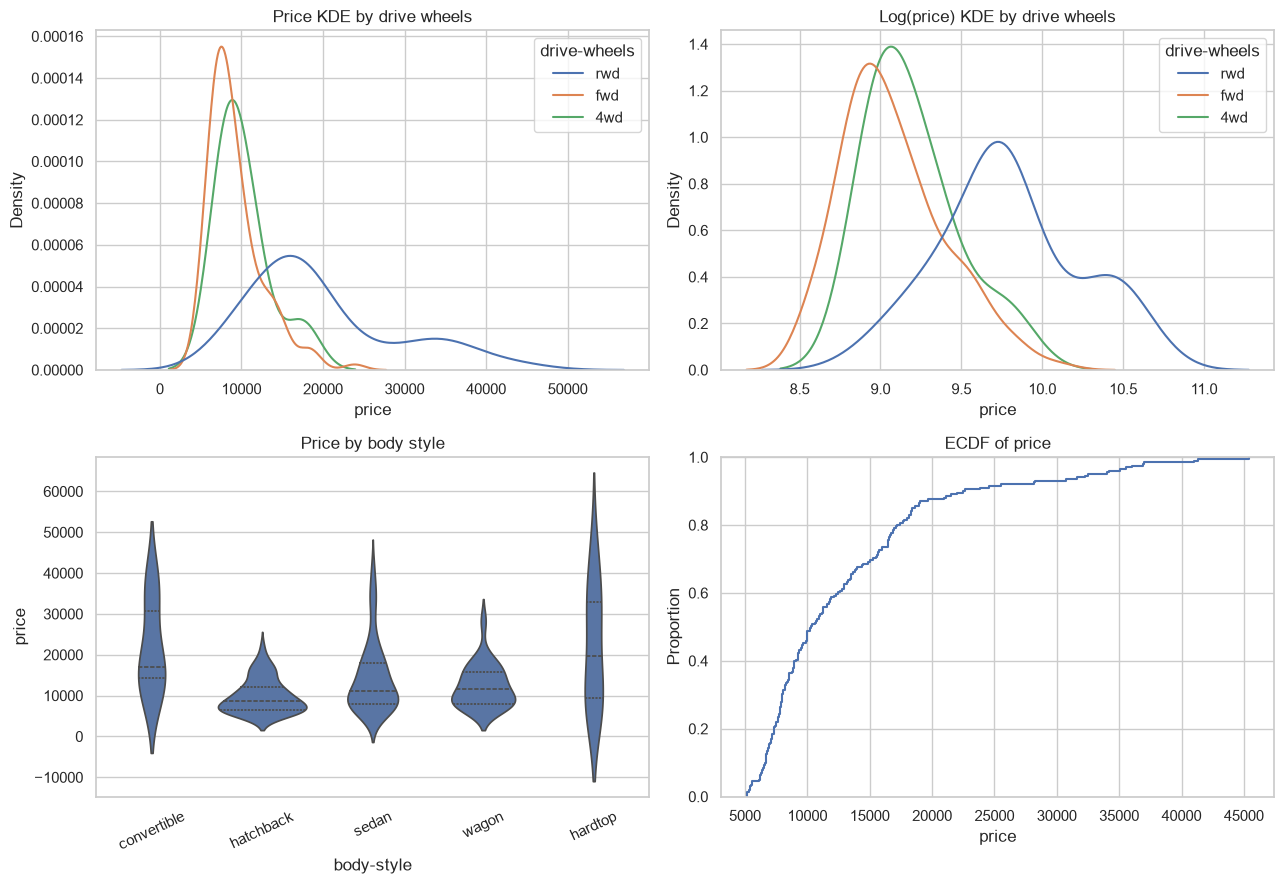

Price quartiles: {0.25: 7775.0, 0.5: 10295.0, 0.75: 16500.0}
Price range: $5,118–$45,400


In [9]:
log_price = np.log(df["price"])
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.kdeplot(data=df, x="price", hue="drive-wheels", common_norm=False, ax=axes[0, 0])
axes[0, 0].set_title("Price KDE by drive wheels")
sns.kdeplot(x=log_price, hue=df["drive-wheels"], common_norm=False, ax=axes[0, 1])
axes[0, 1].set_title("Log(price) KDE by drive wheels")
sns.violinplot(data=df, x="body-style", y="price", inner="quart", ax=axes[1, 0])
axes[1, 0].tick_params(axis="x", rotation=25)
axes[1, 0].set_title("Price by body style")
sns.ecdfplot(data=df, x="price", ax=axes[1, 1])
axes[1, 1].set_title("ECDF of price")
plt.tight_layout()
plt.show()
print(
    "Price quartiles:",
    df["price"].quantile([0.25, 0.50, 0.75]).round(2).to_dict(),
)
print(
    "Price range:",
    f"${df['price'].min():,.0f}–${df['price'].max():,.0f}",
)

The price distribution spans **$5,118–$45,400**; its quartiles are **$7,775**, **$10,295**, and **$16,500** (25th, 50th, and 75th percentiles). The KDEs contrast raw and log-price scales, the violin separates price by body style, and the ECDF shows the proportion below any chosen price; the median ECDF level is **50%** by definition.

In [10]:
price_transformations = {
    "price": df["price"].to_numpy(),
    "log(price)": np.log(df["price"].to_numpy()),
}
boxcox_values, boxcox_lambda = stats.boxcox(df["price"].to_numpy())
price_transformations["Box-Cox(price)"] = boxcox_values

normality_rows = []
for label, values in price_transformations.items():
    k2 = stats.normaltest(values)
    ad = stats.anderson(values, dist="norm")
    five_percent_index = list(ad.significance_level).index(5.0)
    critical_5pct = ad.critical_values[five_percent_index]
    normality_rows.append(
        {
            "scale": label,
            "D_Agostino_K2": k2.statistic,
            "K2_p_value": k2.pvalue,
            "Anderson_Darling": ad.statistic,
            "AD_5pct_critical": critical_5pct,
            "AD_reject_at_5pct": bool(ad.statistic > critical_5pct),
        }
    )
normality_report = pd.DataFrame(normality_rows).set_index("scale")
display(normality_report)
print(f"Box-Cox lambda: {boxcox_lambda:.6f}")

,D_Agostino_K2,K2_p_value,Anderson_Darling,AD_5pct_critical,AD_reject_at_5pct
scale,,,,,
price,78.3738,0.0000,12.0507,0.7490,True
log(price),13.9208,0.0009,2.8873,0.7490,True
Box-Cox(price),16.0911,0.0003,1.1913,0.7490,True


Box-Cox lambda: -0.629546


All three scales still reject normality at 5%. For raw price, K² = **78.3738** (p < **0.001**) and AD = **12.0507**; for log(price), K² = **13.9208** (p = **0.0009**) and AD = **2.8873**; for Box–Cox(price), K² = **16.0911** (p = **0.0003**) and AD = **1.1913**. Each AD statistic exceeds the **0.7490** 5% critical value. Box–Cox uses λ = **−0.629546**, but does not make price normal.

## Question 3 — Grouped prices and one-way ANOVA

In [11]:
def safe_name(name):
    return re.sub(r"\W+", "_", name).strip("_")

original_for_safe = {safe_name(column): column for column in df.columns}
data = df.rename(columns={column: safe_name(column) for column in df.columns})
data["log_price"] = np.log(data["price"])

drive_summary = (
    data.groupby("drive_wheels", observed=True)["price"]
    .agg(n="size", mean_price="mean", median_price="median")
    .sort_values("mean_price", ascending=False)
)
body_summary = (
    data.groupby("body_style", observed=True)["price"]
    .agg(n="size", mean_price="mean", median_price="median")
    .sort_values("mean_price", ascending=False)
)
price_pivot = pd.pivot_table(
    data,
    index="drive_wheels",
    columns="body_style",
    values="price",
    aggfunc="mean",
    margins=True,
    margins_name="All",
    observed=True,
)
display(drive_summary)
display(body_summary)
display(price_pivot)
highest_drive = drive_summary["mean_price"].idxmax()
lowest_drive = drive_summary["mean_price"].idxmin()
highest_body = body_summary["mean_price"].idxmax()
lowest_body = body_summary["mean_price"].idxmin()
highest_cell = price_pivot.drop(index="All", errors="ignore").drop(columns="All", errors="ignore").stack().idxmax()
lowest_cell = price_pivot.drop(index="All", errors="ignore").drop(columns="All", errors="ignore").stack().idxmin()
print(f"Drive wheels: highest mean = {highest_drive} (${drive_summary.loc[highest_drive, 'mean_price']:,.2f}); lowest = {lowest_drive} (${drive_summary.loc[lowest_drive, 'mean_price']:,.2f})")
print(f"Body style: highest mean = {highest_body} (${body_summary.loc[highest_body, 'mean_price']:,.2f}); lowest = {lowest_body} (${body_summary.loc[lowest_body, 'mean_price']:,.2f})")
print(f"Highest observed drive-wheel × body-style cell: {highest_cell}; lowest: {lowest_cell}")

,n,mean_price,median_price
drive_wheels,,,
rwd,75,"19,757.6133","16,900.0000"
4wd,8,"10,241.0000","9,005.5000"
fwd,118,"9,244.7797","8,192.0000"


,n,mean_price,median_price
body_style,,,
hardtop,8,"22,208.5000","19,687.5000"
convertible,6,"21,890.5000","17,084.5000"
sedan,94,"14,459.7553","11,078.5000"
wagon,25,"12,371.9600","11,694.0000"
hatchback,68,"9,957.4412","8,672.0000"


body_style,convertible,hardtop,hatchback,sedan,wagon,All
drive_wheels,,,,,,
4wd,NaN,NaN,"7,603.0000","12,647.3333","9,095.7500","10,241.0000"
fwd,"11,595.0000","8,249.0000","8,396.3878","9,811.8000","9,997.3333","9,244.7797"
rwd,"23,949.6000","24,202.7143","14,337.7778","21,711.8333","16,994.2222","19,757.6133"
All,"21,890.5000","22,208.5000","9,957.4412","14,459.7553","12,371.9600","13,207.1294"


Drive wheels: highest mean = rwd ($19,757.61); lowest = fwd ($9,244.78)
Body style: highest mean = hardtop ($22,208.50); lowest = hatchback ($9,957.44)
Highest observed drive-wheel × body-style cell: ('rwd', 'hardtop'); lowest: ('4wd', 'hatchback')


The marginal means rank **rwd highest at $19,757.61** and **fwd lowest at $9,244.78**; by body style, **hardtop is highest at $22,208.50** and **hatchback lowest at $9,957.44**. The pivot's grand mean is **$13,207.13**. Among observed combinations, rwd/hardtop averages **$24,202.71**, while 4wd/hatchback averages **$7,603.00**; empty cells are unobserved, not zero-price groups.

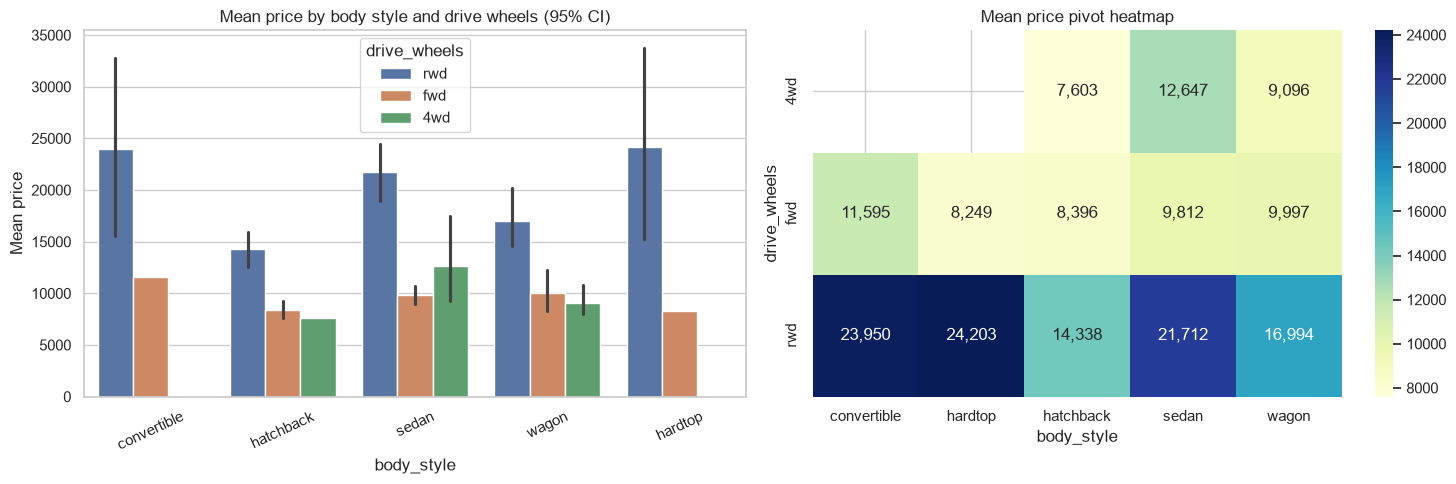

Pivot grand mean: $13,207.13


body_style,convertible,hardtop,hatchback,sedan,wagon,All
drive_wheels,,,,,,
4wd,NaN,NaN,"7,603.0000","12,647.3333","9,095.7500","10,241.0000"
fwd,"11,595.0000","8,249.0000","8,396.3878","9,811.8000","9,997.3333","9,244.7797"
rwd,"23,949.6000","24,202.7143","14,337.7778","21,711.8333","16,994.2222","19,757.6133"
All,"21,890.5000","22,208.5000","9,957.4412","14,459.7553","12,371.9600","13,207.1294"


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(
    data=data, x="body_style", y="price", hue="drive_wheels",
    errorbar=("ci", 95), ax=axes[0],
)
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_title("Mean price by body style and drive wheels (95% CI)")
axes[0].set_ylabel("Mean price")
sns.heatmap(price_pivot.iloc[:-1, :-1], annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[1])
axes[1].set_title("Mean price pivot heatmap")
plt.tight_layout()
plt.show()
print(f"Pivot grand mean: ${price_pivot.loc['All', 'All']:,.2f}")
display(price_pivot)

The grouped bars and heatmap visualize the same pivot: the observed rwd/hardtop cell is **$24,202.71**, versus **$7,603.00** for 4wd/hatchback, and the overall margin is **$13,207.13**. The 95% intervals and missing cells highlight why small combinations should not be overinterpreted.

In [13]:
drive_groups = [
    group["price"].to_numpy()
    for _, group in data.groupby("drive_wheels", observed=True)
]
levene_drive = stats.levene(*drive_groups, center="median")
drive_anova_model = ols("price ~ C(drive_wheels)", data=data).fit()
drive_anova = anova_lm(drive_anova_model, typ=2)
tukey_drive = pairwise_tukeyhsd(
    endog=data["price"],
    groups=data["drive_wheels"],
    alpha=0.05,
)
display(drive_anova)
print(f"Levene median-centered: statistic={levene_drive.statistic:.4f}, p={levene_drive.pvalue:.6g}")
print(tukey_drive)

,sum_sq,df,F,PR(>F)
C(drive_wheels),"5,141,171,794.5789",2.0000,67.9541,0.0000
Residual,"7,490,000,894.0579",198.0000,NaN,NaN


Levene median-centered: statistic=18.4887, p=4.34763e-08
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
group1 group2  meandiff  p-adj    lower      upper    reject
------------------------------------------------------------
   4wd    fwd  -996.2203 0.8974 -6302.5087   4310.068  False
   4wd    rwd  9516.6133 0.0001  4114.6082 14918.6184   True
   fwd    rwd 10512.8337    0.0  8367.9755 12657.6919   True
------------------------------------------------------------


The drive-wheel ANOVA is significant (**F = 67.9541, p < 0.001**), but Levene's test also rejects equal variances (**statistic = 18.4887, p = 4.35 × 10⁻⁸**), so conventional ANOVA/Tukey inference is qualified. Tukey finds rwd above fwd by **$10,512.83** (adjusted p < 0.001) and above 4wd by **$9,516.61** (p = 0.0001); 4wd versus fwd differs by **−$996.22** and is not significant (p = 0.8974).

## Question 4(a) — Continuous variables versus price

In [14]:
continuous_model_features = [
        safe_name(column) for column in continuous_features
    if column != "price"
]
simple_models = {}
simple_rows = []
for feature in continuous_model_features:
    model = ols(f"log_price ~ {feature}", data=data).fit()
    simple_models[feature] = model
    simple_rows.append(
        {
            "predictor": feature,
            "slope": model.params[feature],
            "R_squared": model.rsquared,
            "p_value": model.pvalues[feature],
        }
    )
simple_ols_report = (
    pd.DataFrame(simple_rows)
    .sort_values("R_squared", ascending=False)
    .reset_index(drop=True)
)
display(simple_ols_report)
top_four_predictors = simple_ols_report.head(4)["predictor"].tolist()
print("Top four by univariate R²:", top_four_predictors)

,predictor,slope,R_squared,p_value
0,curb_weight,0.0009,0.7947,0.0000
1,horsepower,0.0112,0.6930,0.0000
2,city_L_100km,0.1648,0.6915,0.0000
3,engine_size,0.0100,0.6888,0.0000
4,width,13.7334,0.6369,0.0000
5,highway_mpg,-0.0577,0.6126,0.0000
6,length,6.5849,0.6027,0.0000
7,city_mpg,-0.0606,0.6005,0.0000
8,wheel_base,0.0526,0.4042,0.0000
9,bore,1.1354,0.3672,0.0000


Top four by univariate R²: ['curb_weight', 'horsepower', 'city_L_100km', 'engine_size']


The strongest univariate fit is curb weight (**slope 0.0009, R² = 0.7947, p < 0.001**), followed by horsepower (**0.0112, 0.6930, p < 0.001**), city L/100 km (**0.1648, 0.6915, p < 0.001**), and engine size (**0.0100, 0.6888, p < 0.001**). These are separate associations with log(price), not adjusted effects.

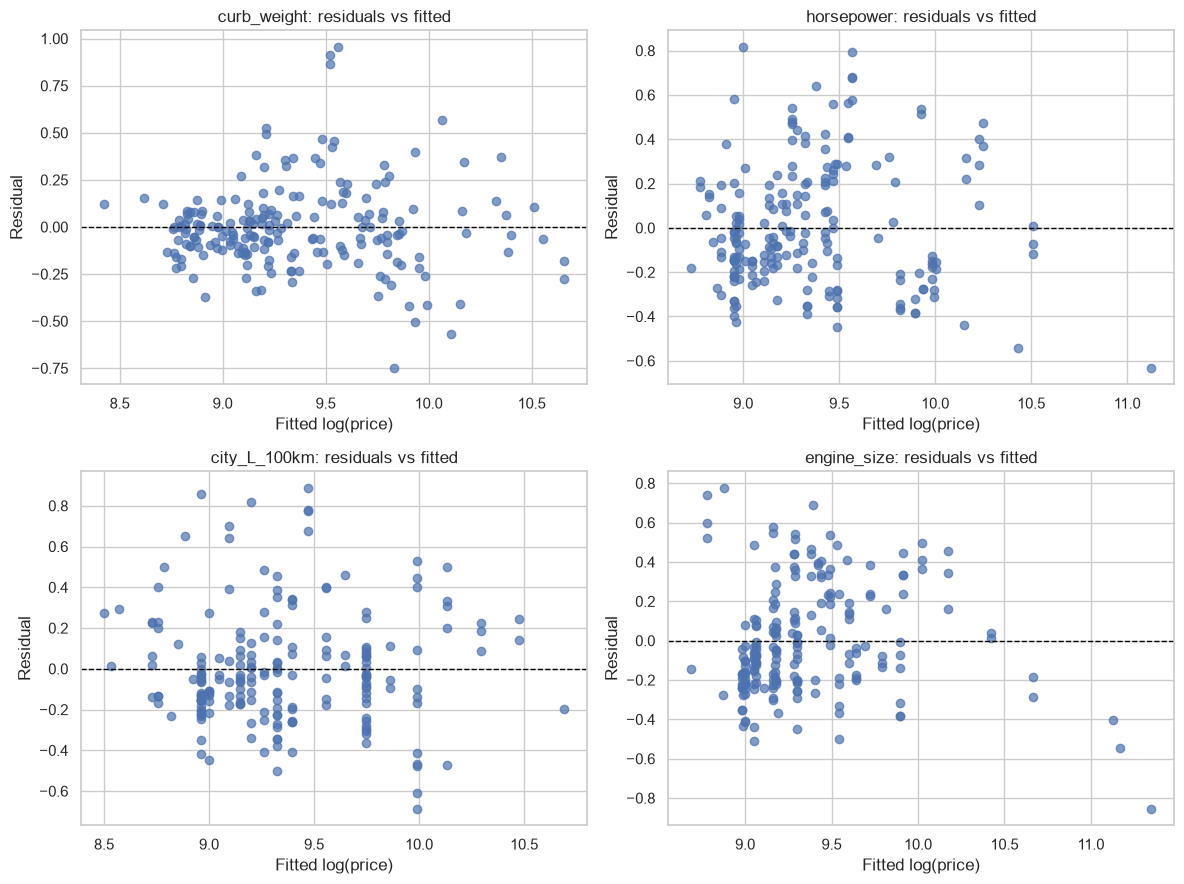

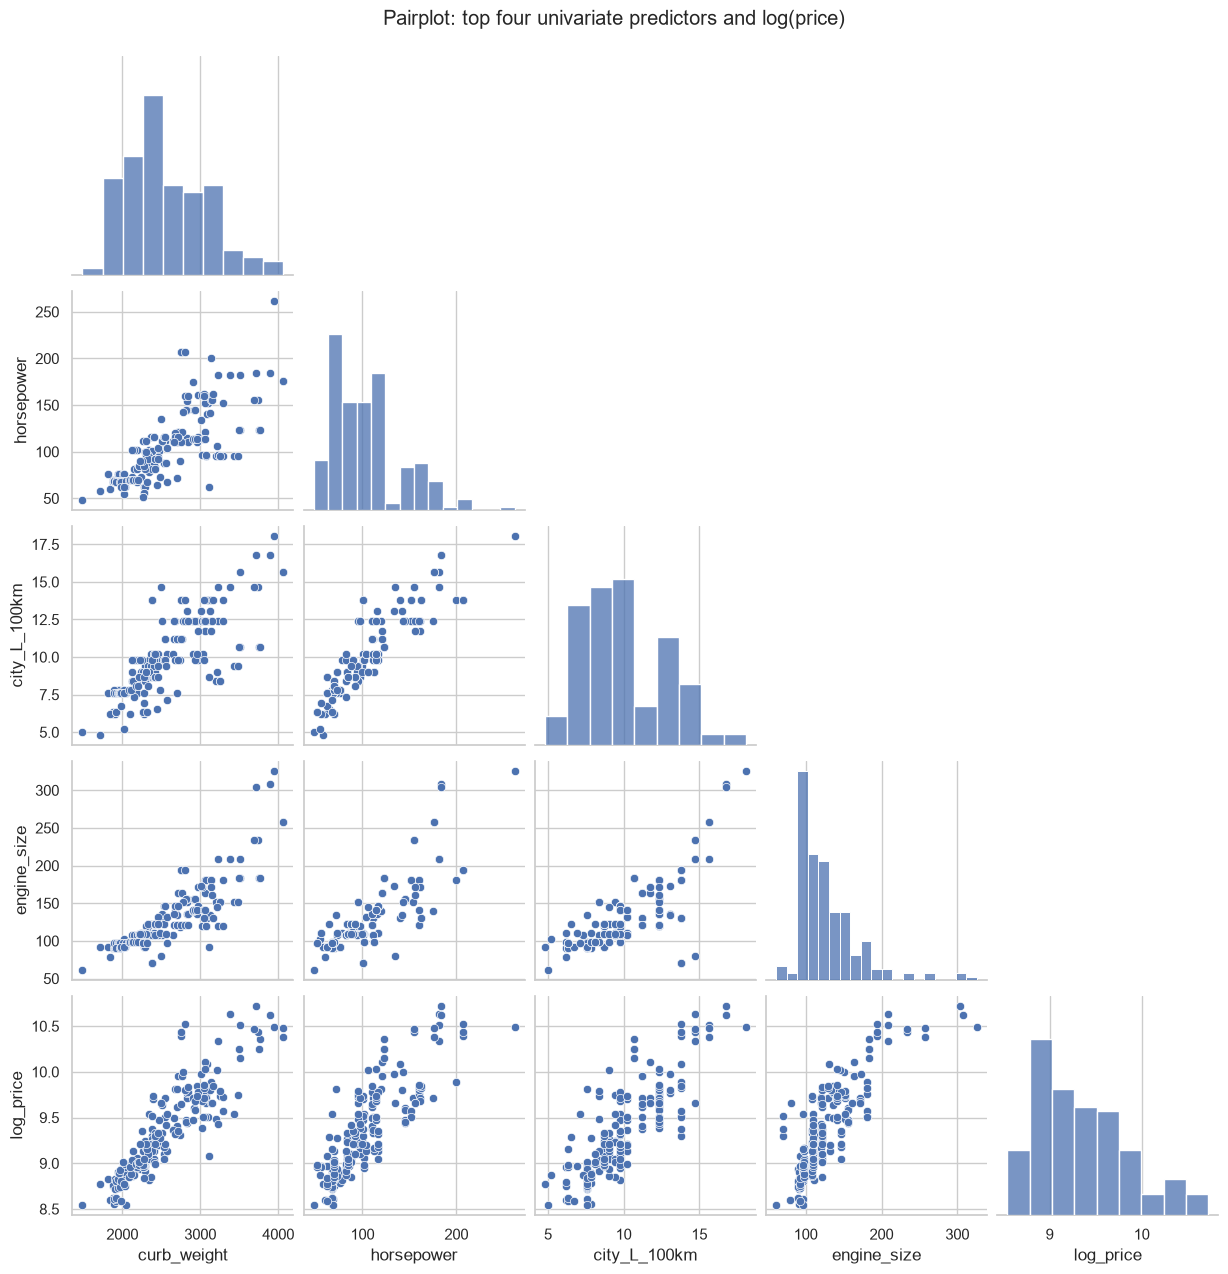

,predictor,slope,R_squared,p_value
0,curb_weight,0.0009,0.7947,0.0000
1,horsepower,0.0112,0.6930,0.0000
2,city_L_100km,0.1648,0.6915,0.0000
3,engine_size,0.0100,0.6888,0.0000


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, feature in zip(axes.flat, top_four_predictors):
    model = simple_models[feature]
    ax.scatter(model.fittedvalues, model.resid, alpha=0.7)
    ax.axhline(0, color="black", linewidth=1, linestyle="--")
    ax.set_title(f"{feature}: residuals vs fitted")
    ax.set_xlabel("Fitted log(price)")
    ax.set_ylabel("Residual")
plt.tight_layout()
plt.show()

pairplot_data = data[top_four_predictors + ["log_price"]]
pair_grid = sns.pairplot(pairplot_data, corner=True, diag_kind="hist")
pair_grid.fig.suptitle("Pairplot: top four univariate predictors and log(price)", y=1.02)
plt.show()
display(simple_ols_report.head(4))

The residual and pair plots use the four reported leaders: **curb weight, horsepower, city L/100 km, and engine size**. Their univariate R² values are **0.7947, 0.6930, 0.6915, and 0.6888**, respectively. The panels make curvature/funneling and predictor overlap visually inspectable; the high pairwise associations also motivate VIF screening.

## Question 4(b) — Categorical attributes versus price

In [16]:
categorical_features = [
        safe_name(column) for column in categorical_columns
    if column != "horsepower-binned"
]
categorical_anova_rows = []
for feature in categorical_features:
    model = ols(f"price ~ C({feature})", data=data).fit()
    table = anova_lm(model, typ=2)
    factor_row = table.loc[f"C({feature})"]
    residual_row = table.loc["Residual"]
    total_ss = ((data["price"] - data["price"].mean()) ** 2).sum()
    mse = residual_row["sum_sq"] / residual_row["df"]
    omega_squared = (
        factor_row["sum_sq"] - factor_row["df"] * mse
    ) / (total_ss + mse)
    categorical_anova_rows.append(
        {
            "attribute": feature,
            "levels": data[feature].nunique(),
            "F": factor_row["F"],
            "p_value": factor_row["PR(>F)"],
            "omega_squared": omega_squared,
        }
    )
categorical_anova_report = (
    pd.DataFrame(categorical_anova_rows)
    .sort_values("omega_squared", ascending=False)
    .reset_index(drop=True)
)
display(categorical_anova_report)
print("Largest estimated categorical effect:", categorical_anova_report.iloc[0]["attribute"])
print("Smallest estimated categorical effect:", categorical_anova_report.iloc[-1]["attribute"])

,attribute,levels,F,p_value,omega_squared
0,make,22,33.2321,0.0000,0.7710
1,num_of_cylinders,7,54.9437,0.0000,0.6169
2,drive_wheels,3,67.9541,0.0000,0.3998
3,fuel_system,8,15.0244,0.0000,0.3281
4,engine_type,6,9.8451,0.0000,0.1803
5,body_style,5,9.1288,0.0000,0.1392
6,engine_location,2,24.4956,0.0000,0.1047
7,aspiration,2,6.6313,0.0107,0.0273
8,num_of_doors,2,0.3590,0.5497,-0.0032


Largest estimated categorical effect: make
Smallest estimated categorical effect: num_of_doors


Make has the largest unadjusted categorical effect (**ω² = 0.7710, F = 33.2321, p < 0.001**), followed by cylinder count (**0.6169**) and drive wheels (**0.3998**). Door count is the smallest (**ω² = −0.0032, p = 0.5497**), providing no evidence of a one-way mean-price difference. These are unadjusted effects and do not imply causation.

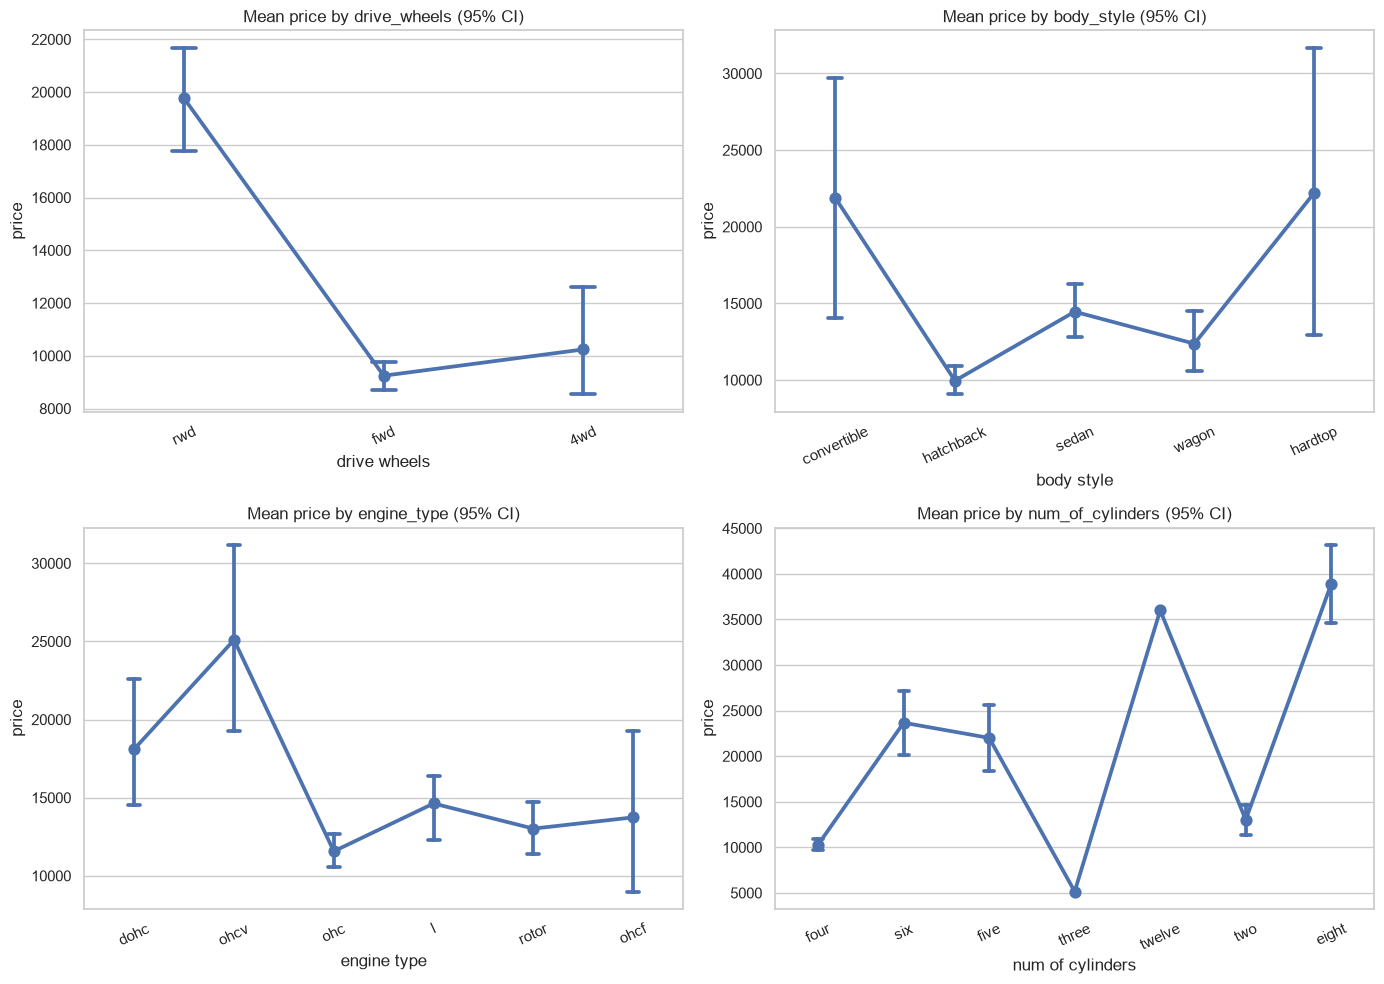

,attribute,category,n,mean_price
0,drive_wheels,4wd,8,"10,241.0000"
1,drive_wheels,fwd,118,"9,244.7797"
2,drive_wheels,rwd,75,"19,757.6133"
3,body_style,convertible,6,"21,890.5000"
4,body_style,hardtop,8,"22,208.5000"
5,body_style,hatchback,68,"9,957.4412"
6,body_style,sedan,94,"14,459.7553"
7,body_style,wagon,25,"12,371.9600"
8,engine_type,dohc,12,"18,116.4167"
9,engine_type,l,12,"14,627.5833"


In [17]:
plot_categories = ["drive_wheels", "body_style", "engine_type", "num_of_cylinders"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, feature in zip(axes.flat, plot_categories):
    sns.pointplot(
        data=data, x=feature, y="price", errorbar=("ci", 95),
        capsize=0.12, ax=ax,
    )
    ax.set_title(f"Mean price by {feature} (95% CI)")
    ax.tick_params(axis="x", rotation=25)
    ax.set_xlabel(feature.replace("_", " "))
plt.tight_layout()
plt.show()
pointplot_means = pd.concat(
    [
        data.groupby(feature, observed=True)["price"]
        .agg(n="size", mean_price="mean")
        .assign(attribute=feature)
        .reset_index(names="category")
        for feature in plot_categories
    ],
    ignore_index=True,
)
display(pointplot_means[["attribute", "category", "n", "mean_price"]])

The point plots show the observed price separation: mean rwd price is **$19,757.61** versus **$9,244.78** for fwd, and hardtop is **$22,208.50** versus **$9,957.44** for hatchback. The 95% intervals communicate uncertainty, particularly for sparse groups; the corresponding categorical ANOVA and ω² values are in the preceding table.

## Question 4(c) — Two-way ANOVA and interaction

In [18]:
two_way_model = ols(
    "price ~ C(drive_wheels) * C(body_style)",
    data=data,
).fit()
two_way_anova = anova_lm(two_way_model, typ=2)
display(two_way_anova)
print(f"Interaction term p-value: {two_way_anova.loc['C(drive_wheels):C(body_style)', 'PR(>F)']:.6g}")

C:\Users\HP\AppData\Local\Temp\ipykernel_21636\1344506737.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit()


,sum_sq,df,F,PR(>F)
C(drive_wheels),"5,865,029,108.5051",2.0000,85.7003,0.0000
C(body_style),"514,683,421.3018",4.0000,3.7603,0.0057
C(drive_wheels):C(body_style),"544,992,833.3056",8.0000,1.9909,0.0496
Residual,"6,433,031,710.8112",188.0000,NaN,NaN


Interaction term p-value: 0.0496332


Type II ANOVA finds drive-wheel (**F = 85.7003, p < 0.001**) and body-style (**F = 3.7603, p = 0.0057**) main effects. The interaction is borderline at **F = 1.9909, p = 0.0496**. The output also warns that the design is rank-deficient because some drive-wheel/body-style combinations are absent (including 4wd hardtop and convertible); treat this interaction p-value as exploratory rather than definitive.

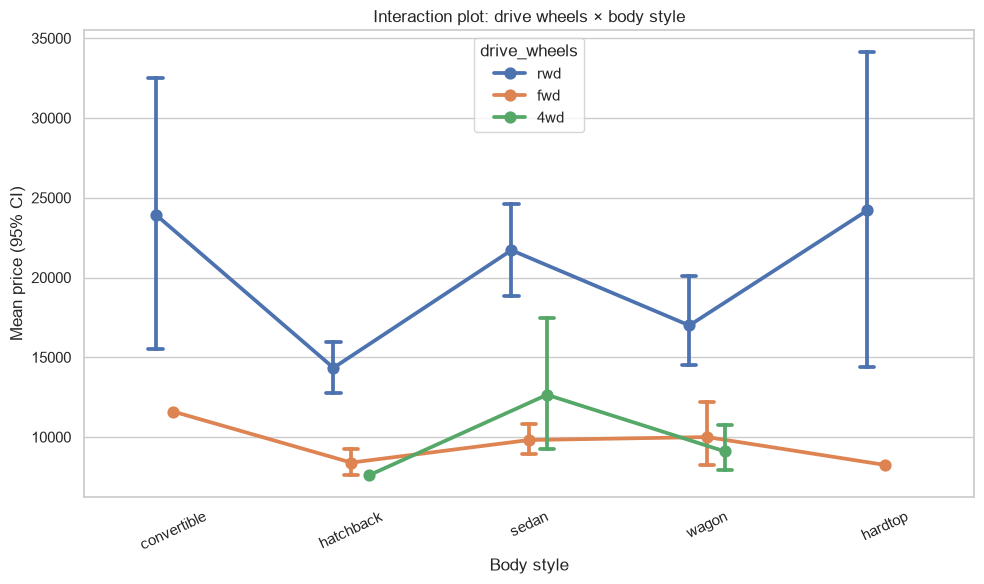

body_style,convertible,hardtop,hatchback,sedan,wagon
drive_wheels,,,,,
4wd,NaN,NaN,"7,603.0000","12,647.3333","9,095.7500"
fwd,"11,595.0000","8,249.0000","8,396.3878","9,811.8000","9,997.3333"
rwd,"23,949.6000","24,202.7143","14,337.7778","21,711.8333","16,994.2222"


Interaction test p-value: 0.0496332


In [19]:
plt.figure(figsize=(10, 6))
sns.pointplot(
    data=data, x="body_style", y="price", hue="drive_wheels",
    errorbar=("ci", 95), dodge=0.2, capsize=0.08,
)
plt.title("Interaction plot: drive wheels × body style")
plt.xlabel("Body style")
plt.ylabel("Mean price (95% CI)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()
interaction_means = pd.pivot_table(
    data, index="drive_wheels", columns="body_style",
    values="price", aggfunc="mean", observed=True,
)
display(interaction_means)
print(
    "Interaction test p-value:",
    f"{two_way_anova.loc['C(drive_wheels):C(body_style)', 'PR(>F)']:.6g}",
)

The plotted profiles correspond to the Type II interaction test (**p = 0.0496**). The 4wd group has no hardtop or convertible observations, so those combinations have no plotted mean; this sparse support is the reason the fitted interaction design is rank-deficient and limits the interpretation of apparent non-parallel profiles.

## Question 5 — Feature selection and final OLS model

In [20]:
# VIF is assessed on continuous predictors only; categorical effects are jointly tested in backward selection.
vif_features = [safe_name(feature) for feature in continuous_features if feature != "price"]
vif_frame = pd.DataFrame(
    {safe_name(feature): df[f"{feature}_winsorized"] for feature in continuous_features if feature != "price"}
)
vif_history = []
while len(vif_frame.columns) > 1:
    vif_values = pd.Series(
        [
            variance_inflation_factor(vif_frame.to_numpy(dtype=float), index)
            for index in range(vif_frame.shape[1])
        ],
        index=vif_frame.columns,
        name="VIF",
    )
    worst_feature = vif_values.idxmax()
    worst_vif = float(vif_values.max())
    vif_history.append(
        {
            "iteration": len(vif_history) + 1,
            "dropped": worst_feature if worst_vif > 10 else "—",
            "maximum_VIF": worst_vif,
            "remaining_predictors": len(vif_frame.columns),
        }
    )
    if worst_vif <= 10:
        break
    vif_frame = vif_frame.drop(columns=worst_feature)

vif_report = pd.DataFrame(vif_history)
display(vif_report)
print("Continuous predictors retained after VIF:", list(vif_frame.columns))
print("Final maximum VIF:", f"{vif_report.iloc[-1]['maximum_VIF']:.4f}")

,iteration,dropped,maximum_VIF,remaining_predictors
0,1,city_mpg,39.7187,15
1,2,curb_weight,16.5398,14
2,3,city_L_100km,14.9750,13
3,4,—,8.1281,12


Continuous predictors retained after VIF: ['normalized_losses', 'wheel_base', 'length', 'width', 'height', 'engine_size', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'highway_mpg']
Final maximum VIF: 8.1281


Iterative VIF screening removes **city_mpg (39.7187)**, **curb_weight (16.5398)**, and **city_L_100km (14.9750)**. The final set has **12 continuous predictors**, and its maximum VIF is **8.1281**, below the requested threshold of **10**.

In [21]:
selected_numeric = list(vif_frame.columns)
selected_categorical = [
    feature for feature in categorical_features
    if data[feature].nunique() > 1
]
model_data = pd.DataFrame({"log_price": data["log_price"]})
for feature in selected_numeric:
    original_name = original_for_safe[feature]
    model_data[feature] = df[f"{original_name}_winsorized"]
categorical_collapse = []
for feature in selected_categorical:
    shares = data[feature].value_counts(normalize=True)
    rare_levels = shares[shares < 0.05].index
    model_data[feature] = data[feature].astype("object").where(
        ~data[feature].isin(rare_levels), "Other"
    )
    categorical_collapse.append(
        {
            "attribute": feature,
            "original_levels": data[feature].nunique(),
            "rare_levels_pooled": len(rare_levels),
            "model_levels": model_data[feature].nunique(),
        }
    )
display(pd.DataFrame(categorical_collapse))

terms = selected_numeric + [f"C({feature})" for feature in selected_categorical]

def formula_for_terms(term_list):
    rhs = " + ".join(term_list) if term_list else "1"
    return f"log_price ~ {rhs}"

def fit_terms(term_list):
    return ols(formula_for_terms(term_list), data=model_data).fit()

candidate_design = ols(formula_for_terms(terms), data=model_data)
candidate_rank = np.linalg.matrix_rank(candidate_design.exog)
candidate_columns = candidate_design.exog.shape[1]
if candidate_rank < candidate_columns and "C(engine_type)" in terms:
    terms.remove("C(engine_type)")
    selected_categorical.remove("engine_type")
    candidate_design = ols(formula_for_terms(terms), data=model_data)
    revised_rank = np.linalg.matrix_rank(candidate_design.exog)
    revised_columns = candidate_design.exog.shape[1]
    print(
        f"Removed C(engine_type) after rank check: "
        f"{candidate_rank}/{candidate_columns} -> {revised_rank}/{revised_columns}."
    )
    if revised_rank < revised_columns:
        raise ValueError("Candidate model remains rank-deficient after removing engine_type.")
else:
    print(f"Candidate design-matrix rank: {candidate_rank}/{candidate_columns}")

stepwise_model = candidate_design.fit()
stepwise_history = []
while terms:
    eligible = []
    for term in terms:
        reduced_terms = [candidate for candidate in terms if candidate != term]
        reduced_model = fit_terms(reduced_terms)
        comparison = anova_lm(reduced_model, stepwise_model)
        term_p_value = float(comparison.iloc[1]["Pr(>F)"])
        if term_p_value > 0.05 and reduced_model.aic < stepwise_model.aic:
            eligible.append(
                (term_p_value, reduced_model.aic, term, reduced_model)
            )
    if not eligible:
        break
    term_p_value, reduced_aic, removed_term, reduced_model = max(
        eligible, key=lambda item: (item[0], -item[1])
    )
    stepwise_history.append(
        {
            "removed_term": removed_term,
            "joint_p_value": term_p_value,
            "AIC_before": stepwise_model.aic,
            "AIC_after": reduced_aic,
        }
    )
    terms.remove(removed_term)
    stepwise_model = reduced_model

stepwise_report = pd.DataFrame(stepwise_history)
if stepwise_report.empty:
    print("No term met both the p-value and AIC removal criteria.")
else:
    display(stepwise_report)
final_model = stepwise_model
design_rank = np.linalg.matrix_rank(final_model.model.exog)
design_columns = final_model.model.exog.shape[1]
print(f"Final design-matrix rank: {design_rank}/{design_columns}")
if design_rank < design_columns:
    raise ValueError("Final model design matrix is rank-deficient; review sparse or aliased terms.")
print("Final terms:", terms)
print(f"Final model: n={int(final_model.nobs)}, R²={final_model.rsquared:.4f}, adjusted R²={final_model.rsquared_adj:.4f}, AIC={final_model.aic:.4f}")
print(final_model.summary())

,attribute,original_levels,rare_levels_pooled,model_levels
0,make,22,13,10
1,aspiration,2,0,2
2,num_of_doors,2,0,2
3,body_style,5,2,4
4,drive_wheels,3,1,3
5,engine_location,2,1,2
6,engine_type,6,1,6
7,num_of_cylinders,7,5,3
8,fuel_system,8,4,5


Removed C(engine_type) after rank check: 40/41 -> 36/36.


,removed_term,joint_p_value,AIC_before,AIC_after
0,height,0.8272,-190.4249,-192.3667
1,C(aspiration),0.5637,-192.3667,-193.9619
2,engine_size,0.2553,-193.9619,-194.4000


Final design-matrix rank: 33/33
Final terms: ['normalized_losses', 'wheel_base', 'length', 'width', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'highway_mpg', 'C(make)', 'C(num_of_doors)', 'C(body_style)', 'C(drive_wheels)', 'C(engine_location)', 'C(num_of_cylinders)', 'C(fuel_system)']
Final model: n=201, R²=0.9361, adjusted R²=0.9240, AIC=-194.4000
                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.924
Method:                 Least Squares   F-statistic:                     76.96
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           3.52e-84
Time:                        18:28:33   Log-Likelihood:                 130.20
No. Observations:                 201   AIC:                            -194.4
Df Residuals:                     168   BIC:                            -

The candidate factor design initially had rank **40/41**; removing `engine_type` restored full rank (**36/36**), so a separate engine-type coefficient is not identifiable alongside the other factors in this sample. The 5%-pooled, full-rank stepwise model then removes **height** (p = **0.8272**), **aspiration** (p = **0.5637**), and **engine_size** (p = **0.2553**) because each removal lowers AIC. The final design is full rank (**33/33**) with **201** cars, **R² = 0.9361**, adjusted **R² = 0.9240**, and **AIC = −194.4000**.

In [22]:
coefficient_ci = final_model.conf_int()
coefficient_report = pd.DataFrame(
    {
        "coefficient": final_model.params,
        "p_value": final_model.pvalues,
        "percent_price_effect": np.expm1(final_model.params) * 100,
        "CI95_low_percent": np.expm1(coefficient_ci[0]) * 100,
        "CI95_high_percent": np.expm1(coefficient_ci[1]) * 100,
    }
).drop(index="Intercept", errors="ignore")
coefficient_report["percent_effect_per_0.01_unit"] = np.nan
for feature in selected_numeric:
    if feature in coefficient_report.index:
        coefficient_report.loc[feature, "percent_effect_per_0.01_unit"] = (
            np.expm1(final_model.params[feature] * 0.01) * 100
        )
display(coefficient_report)
if "width" in final_model.params.index:
    print(
        "Width effect per 0.01-unit increase:",
        f"{np.expm1(final_model.params['width'] * 0.01) * 100:.2f}%",
    )

driver_rows = []
for term in terms:
    reduced_model = fit_terms([candidate for candidate in terms if candidate != term])
    partial_r2 = (
        (reduced_model.ssr - final_model.ssr) / reduced_model.ssr
        if reduced_model.ssr > 0 else np.nan
    )
    driver_rows.append(
        {
            "term": term,
            "partial_R_squared": partial_r2,
            "joint_p_value": float(anova_lm(reduced_model, final_model).iloc[1]["Pr(>F)"]),
        }
    )
driver_ranking = pd.DataFrame(driver_rows).sort_values(
    "partial_R_squared", ascending=False
).reset_index(drop=True)
display(driver_ranking)
print("Ranked main drivers:", driver_ranking["term"].tolist())

,coefficient,p_value,percent_price_effect,CI95_low_percent,CI95_high_percent,percent_effect_per_0.01_unit
C(make)[T.honda],0.2464,0.0259,27.9469,3.0513,58.8569,NaN
C(make)[T.mazda],-0.0527,0.2176,-5.1373,-12.7913,3.1885,NaN
C(make)[T.mitsubishi],-0.0993,0.0650,-9.4554,-18.5279,0.6274,NaN
C(make)[T.nissan],-0.0985,0.0244,-9.3782,-16.8118,-1.2804,NaN
C(make)[T.peugot],-0.3905,0.0000,-32.3258,-41.3758,-21.8787,NaN
C(make)[T.subaru],-0.3984,0.0000,-32.8619,-42.6232,-21.4400,NaN
C(make)[T.toyota],-0.1751,0.0000,-16.0666,-21.9312,-9.7615,NaN
C(make)[T.volkswagen],-0.0362,0.4919,-3.5578,-13.0690,6.9939,NaN
C(make)[T.volvo],-0.1349,0.0378,-12.6160,-23.0527,-0.7638,NaN
C(num_of_doors)[T.two],-0.0478,0.1772,-4.6704,-11.0874,2.2097,NaN


Width effect per 0.01-unit increase: 3.01%


,term,partial_R_squared,joint_p_value
0,C(make),0.2850,0.0000
1,stroke,0.0976,0.0000
2,C(fuel_system),0.0727,0.0125
3,horsepower,0.0720,0.0004
4,C(engine_location),0.0564,0.0018
5,C(drive_wheels),0.0537,0.0097
6,C(num_of_cylinders),0.0465,0.0183
7,width,0.0463,0.0048
8,C(body_style),0.0439,0.0558
9,peak_rpm,0.0254,0.0379


Ranked main drivers: ['C(make)', 'stroke', 'C(fuel_system)', 'horsepower', 'C(engine_location)', 'C(drive_wheels)', 'C(num_of_cylinders)', 'width', 'C(body_style)', 'peak_rpm', 'bore', 'normalized_losses', 'wheel_base', 'highway_mpg', 'length', 'compression_ratio', 'C(num_of_doors)']


The final model ranks **make first (partial R² = 0.2850)**, then **stroke (0.0976)**, **fuel system (0.0727)**, and **horsepower (0.0720)**. Holding other retained terms fixed, horsepower is associated with **+0.34% per hp** (p = **0.0004**), and width with **+3.01% per 0.01-unit increase** in its normalized measure. Relative to the pooled `Other` make category, Subaru is **−32.86%** (95% CI **−42.62% to −21.44%**, p < **0.001**) and Honda **+27.95%** (95% CI **+3.05% to +58.86%**, p = **0.0259**). These are conditional associations; the pooled reference combines 13 low-frequency makes.

D’Agostino residual normality: K²=3.3876, p=0.18382
Breusch–Pagan LM=42.6845, p=0.0982028; F=1.4155, p=0.0835723
Cook’s distance threshold 4/n=0.01990; observations above threshold=14
Largest Cook's distances (row index, distance):
[(15, 0.0891729073232784), (42, 0.06316291889847658), (163, 0.05057705410156876), (63, 0.04315140827677033), (122, 0.03236938830523303)]


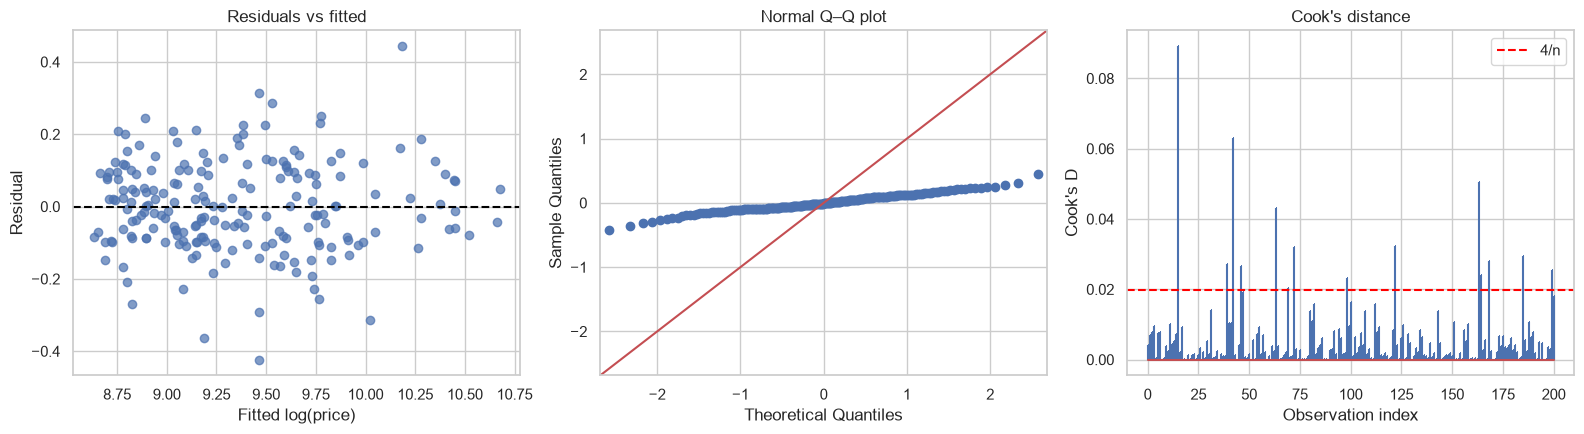

In [23]:
residuals = final_model.resid
fitted = final_model.fittedvalues
normality_residuals = stats.normaltest(residuals)
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(
    residuals, final_model.model.exog
)
cooks_distance = final_model.get_influence().cooks_distance[0]
cook_threshold = 4 / int(final_model.nobs)
influential = np.flatnonzero(
    np.isfinite(cooks_distance) & (cooks_distance > cook_threshold)
)
finite_cooks = [
    (index, float(distance))
    for index, distance in enumerate(cooks_distance)
    if np.isfinite(distance)
]

print(f"D’Agostino residual normality: K²={normality_residuals.statistic:.4f}, p={normality_residuals.pvalue:.6g}")
print(f"Breusch–Pagan LM={bp_lm:.4f}, p={bp_lm_p:.6g}; F={bp_f:.4f}, p={bp_f_p:.6g}")
print(f"Cook’s distance threshold 4/n={cook_threshold:.5f}; observations above threshold={len(influential)}")
print("Largest Cook's distances (row index, distance):")
print(sorted(finite_cooks, key=lambda pair: pair[1], reverse=True)[:5])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(fitted, residuals, alpha=0.7)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(title="Residuals vs fitted", xlabel="Fitted log(price)", ylabel="Residual")
qqplot(residuals, line="45", ax=axes[1])
axes[1].set_title("Normal Q–Q plot")
axes[2].stem(np.arange(len(cooks_distance)), cooks_distance, markerfmt=",")
axes[2].axhline(cook_threshold, color="red", linestyle="--", label="4/n")
axes[2].set(title="Cook's distance", xlabel="Observation index", ylabel="Cook's D")
axes[2].legend()
plt.tight_layout()
plt.show()

Residual normality is not rejected (**K² = 3.3876, p = 0.1838**). Breusch–Pagan is also not significant at 5% (**LM p = 0.0982; F p = 0.0836**), so this sample provides no strong evidence of heteroscedasticity. Cook's threshold is **4/n = 0.01990**; **14 of 201** cars exceed it, with the largest distance **0.08917** at row index **15**. Inspect these observations rather than deleting them automatically.

## Dealer recommendation and limitations

Use the fitted model as a **comparable-sales starting point**, not a price-setting rule. Make is the largest conditional driver (**partial R² = 0.2850**); for example, the model estimates Subaru at **32.86% below** the pooled low-frequency-make reference and Honda at **27.95% above**, holding the retained features constant. For performance tiers, horsepower contributes about **0.34% per additional hp**; the estimated width association is **3.01% per 0.01** in the normalized width measure. Check each estimate against recent local listings and the car's condition before adjusting an asking price.

**Limitations:** the dataset contains only **201 cars** and represents a historical, selected sample; condition, mileage, location, model year, and transaction context are not observed. Prices are strongly non-normal even after log and Box–Cox transformations, Levene's test rejects equal variance across drive wheels, the two-way interaction has missing cells, and **14** observations exceed the Cook's-distance screening threshold. The final OLS diagnostics do not reject residual normality or homoscedasticity at 5%, but sparse groups and feature selection can still make estimates unstable. No holdout or external validation set is available, so treat these associations as descriptive guidance and not causal effects.